# Real phosphorus plots → v1 data → rebuilt plots

**Input:** the six real figures in `step04b_plot_extraction/data/` (used as-is, never cropped).

**Pipeline**

1. **v1 data from the originals.** Every extractor is run on the original images. The classical
   digitizer (axis calibration + colour tracing) gives the most faithful first version, so its v1
   is the one the rebuilt plots are drawn from.
2. **Rebuild.** Each figure is redrawn from that v1 data in matplotlib: same canvas size in pixels,
   plot frame at the same pixel position, same axis limits/ticks/tick direction, fonts (Times-like or
   Arial-like), colours, markers, line widths, legends, broken / dual axes and annotation text. The
   v1 data behind each rebuilt image is saved as its **exact ground truth**.
3. **Extract again.** Every model reads the rebuilt images (and the originals), each in its **own cell**
   below.
4. **Score.** Rebuilt images are scored against exact ground truth (the main, fair comparison:
   same images and same truth for every model). Answers on the originals are scored against the
   v1 reference digitization: an *agreement* score, since nobody has the true raw data of a published
   figure.

**Metric:** error of each point as a % of the y-axis span, capped at 100. Points/series a model
didn't return count as 100 % error. **Accuracy = 100 − mean error over all reference points.**
`coverage` = share of reference points the model returned.

**Models** (one cell each): classical digitizer · Qwen2.5-VL-3B-Instruct · Qwen3-VL-4B-Instruct ·
DePlot · olmOCR-2-7B (native OCR prompt) · olmOCR-2-7B (JSON data prompt) · optional larger
variants (Qwen2.5-VL-7B, Qwen3-VL-8B), off by default.

All answers are cached under `outputs/model_results/<model>/<image_set>/<figure>.json`, raw text
included, so re-running a cell or restarting the kernel never repeats a finished generation.


In [1]:
import importlib, subprocess, sys
from pathlib import Path

# --- dependencies the extraction code needs (the VLM ones are only needed by their own cells)
need = {"scipy": "scipy", "PIL": "pillow", "pandas": "pandas", "matplotlib": "matplotlib"}
missing = [pip for mod, pip in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
for mod, pip in {"torch": "torch", "transformers": "transformers>=4.57", "qwen_vl_utils": "qwen-vl-utils",
                 "accelerate": "accelerate"}.items():
    if importlib.util.find_spec(mod) is None:
        print(f"note: '{mod}' not installed - model cells need it:  pip install '{pip}'")
try:
    import transformers; print("transformers", transformers.__version__)
except ImportError:
    pass

transformers 4.57.6


In [2]:
%matplotlib inline
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
warnings.filterwarnings("ignore", category=UserWarning)

WORK_DIR = Path.cwd()                      # .../step04b_plot_extraction/02_real_plots_multimodel
DATA_DIR = WORK_DIR.parent / "data"        # the six real figures
sys.path.insert(0, str(WORK_DIR))

from chartbench import pipeline as pl
from chartbench.figures import FIGURES, ORDER
from chartbench.models import (ClassicalRunner, QwenVLRunner, Qwen3VLRunner, DePlotRunner,
                               OlmOCRRunner, run_on_images, build_prompt)
from chartbench.scoring import score_figure

P = pl.Paths(WORK_DIR, DATA_DIR)
originals = pl.check_originals(P)
for f in ORDER:
    print(f"{f:9s} {FIGURES[f]['size']}  {FIGURES[f]['title']:55s} <- {FIGURES[f]['file'][:60]}...")

def show_grid(paths, titles, ncols=3, width=18):
    nrows = int(np.ceil(len(paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(width, width / ncols * 0.85 * nrows))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, p, t in zip(np.atleast_1d(axes).ravel(), paths, titles):
        ax.imshow(mpimg.imread(p)); ax.set_title(t, fontsize=10)
    plt.tight_layout(); plt.show()

ftir      (493, 437)  FTIR spectra (stacked, offset curves, no y-ticks)       <- FTIR.png...
pore      (554, 431)  Pore-size distribution (broken y-axis)                  <- Pore.png...
methane   (603, 470)  Cumulative methane yield with error bars                <- Methane.png...
dosage    (687, 526)  Dosage effect, dual y-axes                              <- Dosage.png...
n2        (469, 367)  N2 adsorption-desorption isotherm (hysteresis loop)     <- N2.png...
kinetics  (701, 554)  Adsorption kinetics: data points + three fitted model curves <- Kinetics.png...
ph        (687, 535)  pH of three treatments (single-series bar chart, error bars) <- pH.png...
concentration (698, 559)  Soil nutrients (grouped bars, 3 series, broken y-axis, error bars) <- concentration.png...
concentration2 (701, 523)  Plant quality (grouped bars, broken left axis + right axis, error bars) <- concentration2.png...
climet    (1133, 757)  Impact categories, 2 scenarios (18 categories, 0-100 %) <- climet.png.

## The six original figures (full images, uncropped)

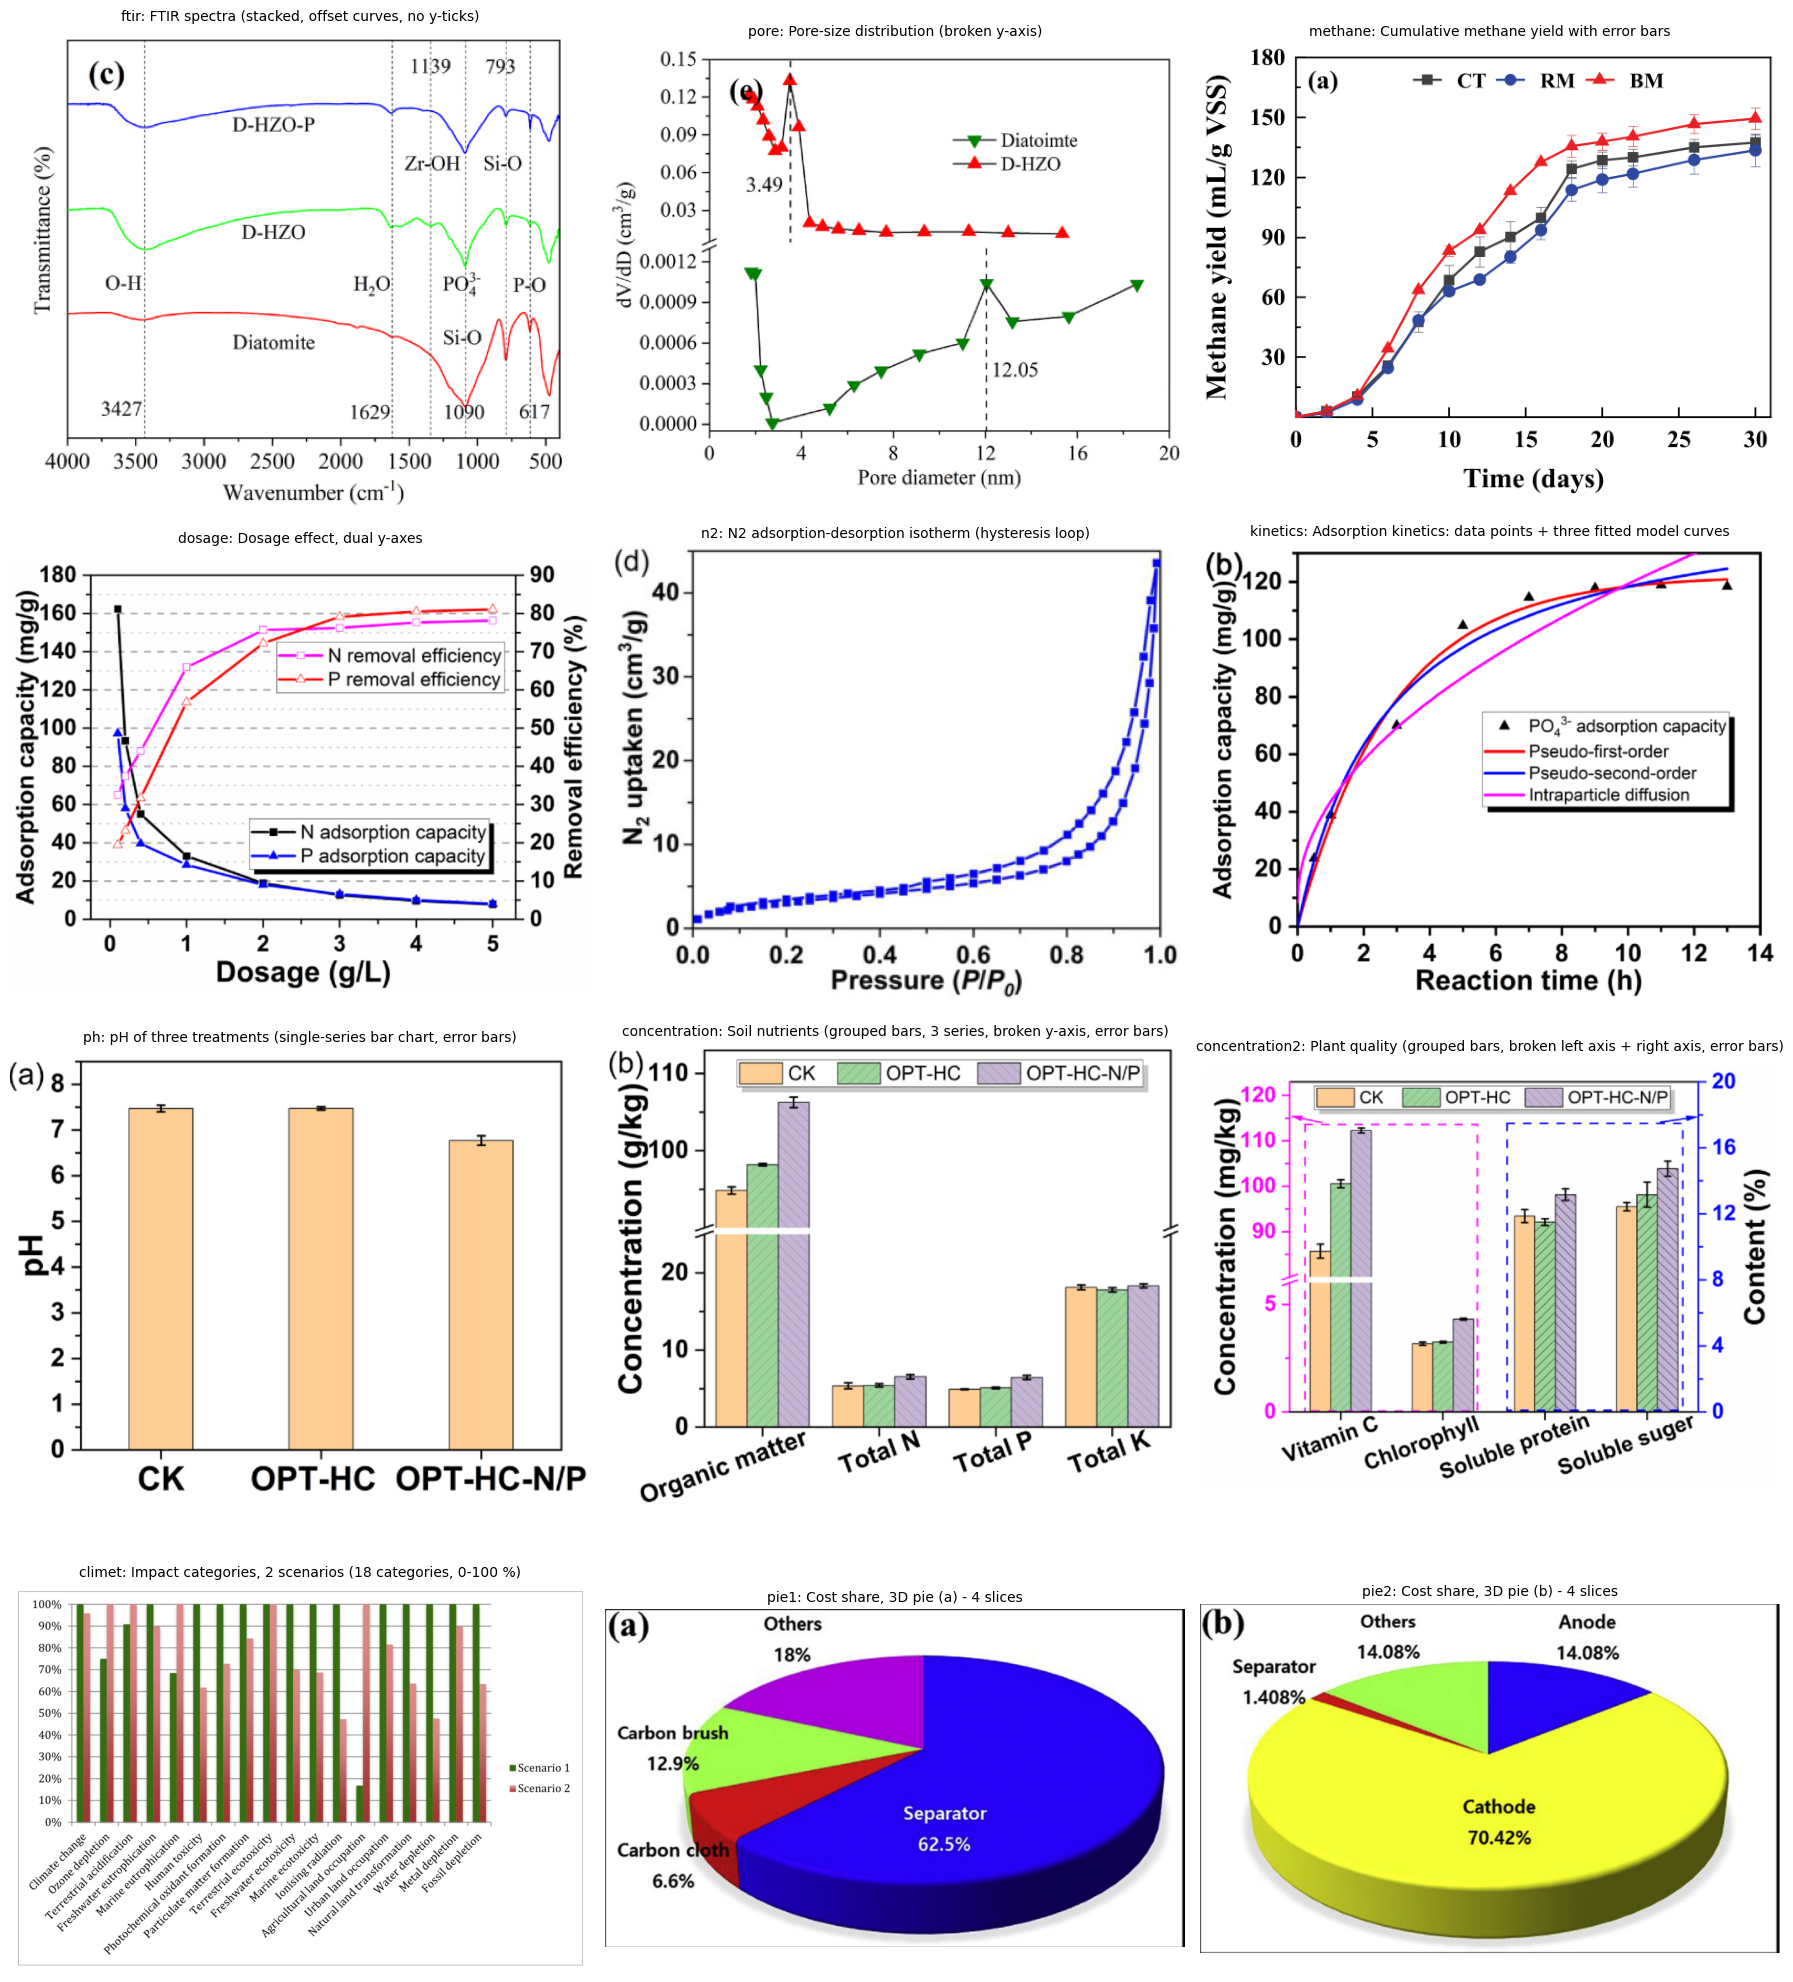

In [3]:
show_grid(originals, [f"{f}: {FIGURES[f]['title']}" for f in ORDER])

## Stage 1 — v1 data from the originals (classical digitizer)

Green = marker/curve found directly, blue = recovered by a local column search (marker half hidden
at the axis origin or cut by a curve), orange = marker fully hidden behind another series' marker,
value taken from the marker it hides behind. Check these overlays: everything downstream is built on
this data.

ftir      3 series,  660 points  
pore      2 series,   31 points  
methane   3 series,   42 points  {'local_search': 2, 'occluded': 7}
dosage    4 series,   32 points  {'local_search': 2, 'occluded': 3}
n2        2 series,   53 points  
kinetics  4 series,  368 points  {'local_search': 2}
ph        1 series,    3 points  {'detected (left axis)': 3}
concentration 3 series,   12 points  {'detected (lower axis)': 9, 'detected (upper axis)': 3}
concentration2 3 series,   12 points  {'detected (lower axis)': 3, 'detected (right axis)': 6, 'detected (upper axis)': 3}
climet    2 series,   36 points  {'detected (left axis)': 36}
pie1      1 series,    4 points  {'printed label': 4}
pie2      1 series,    4 points  {'printed label': 4}


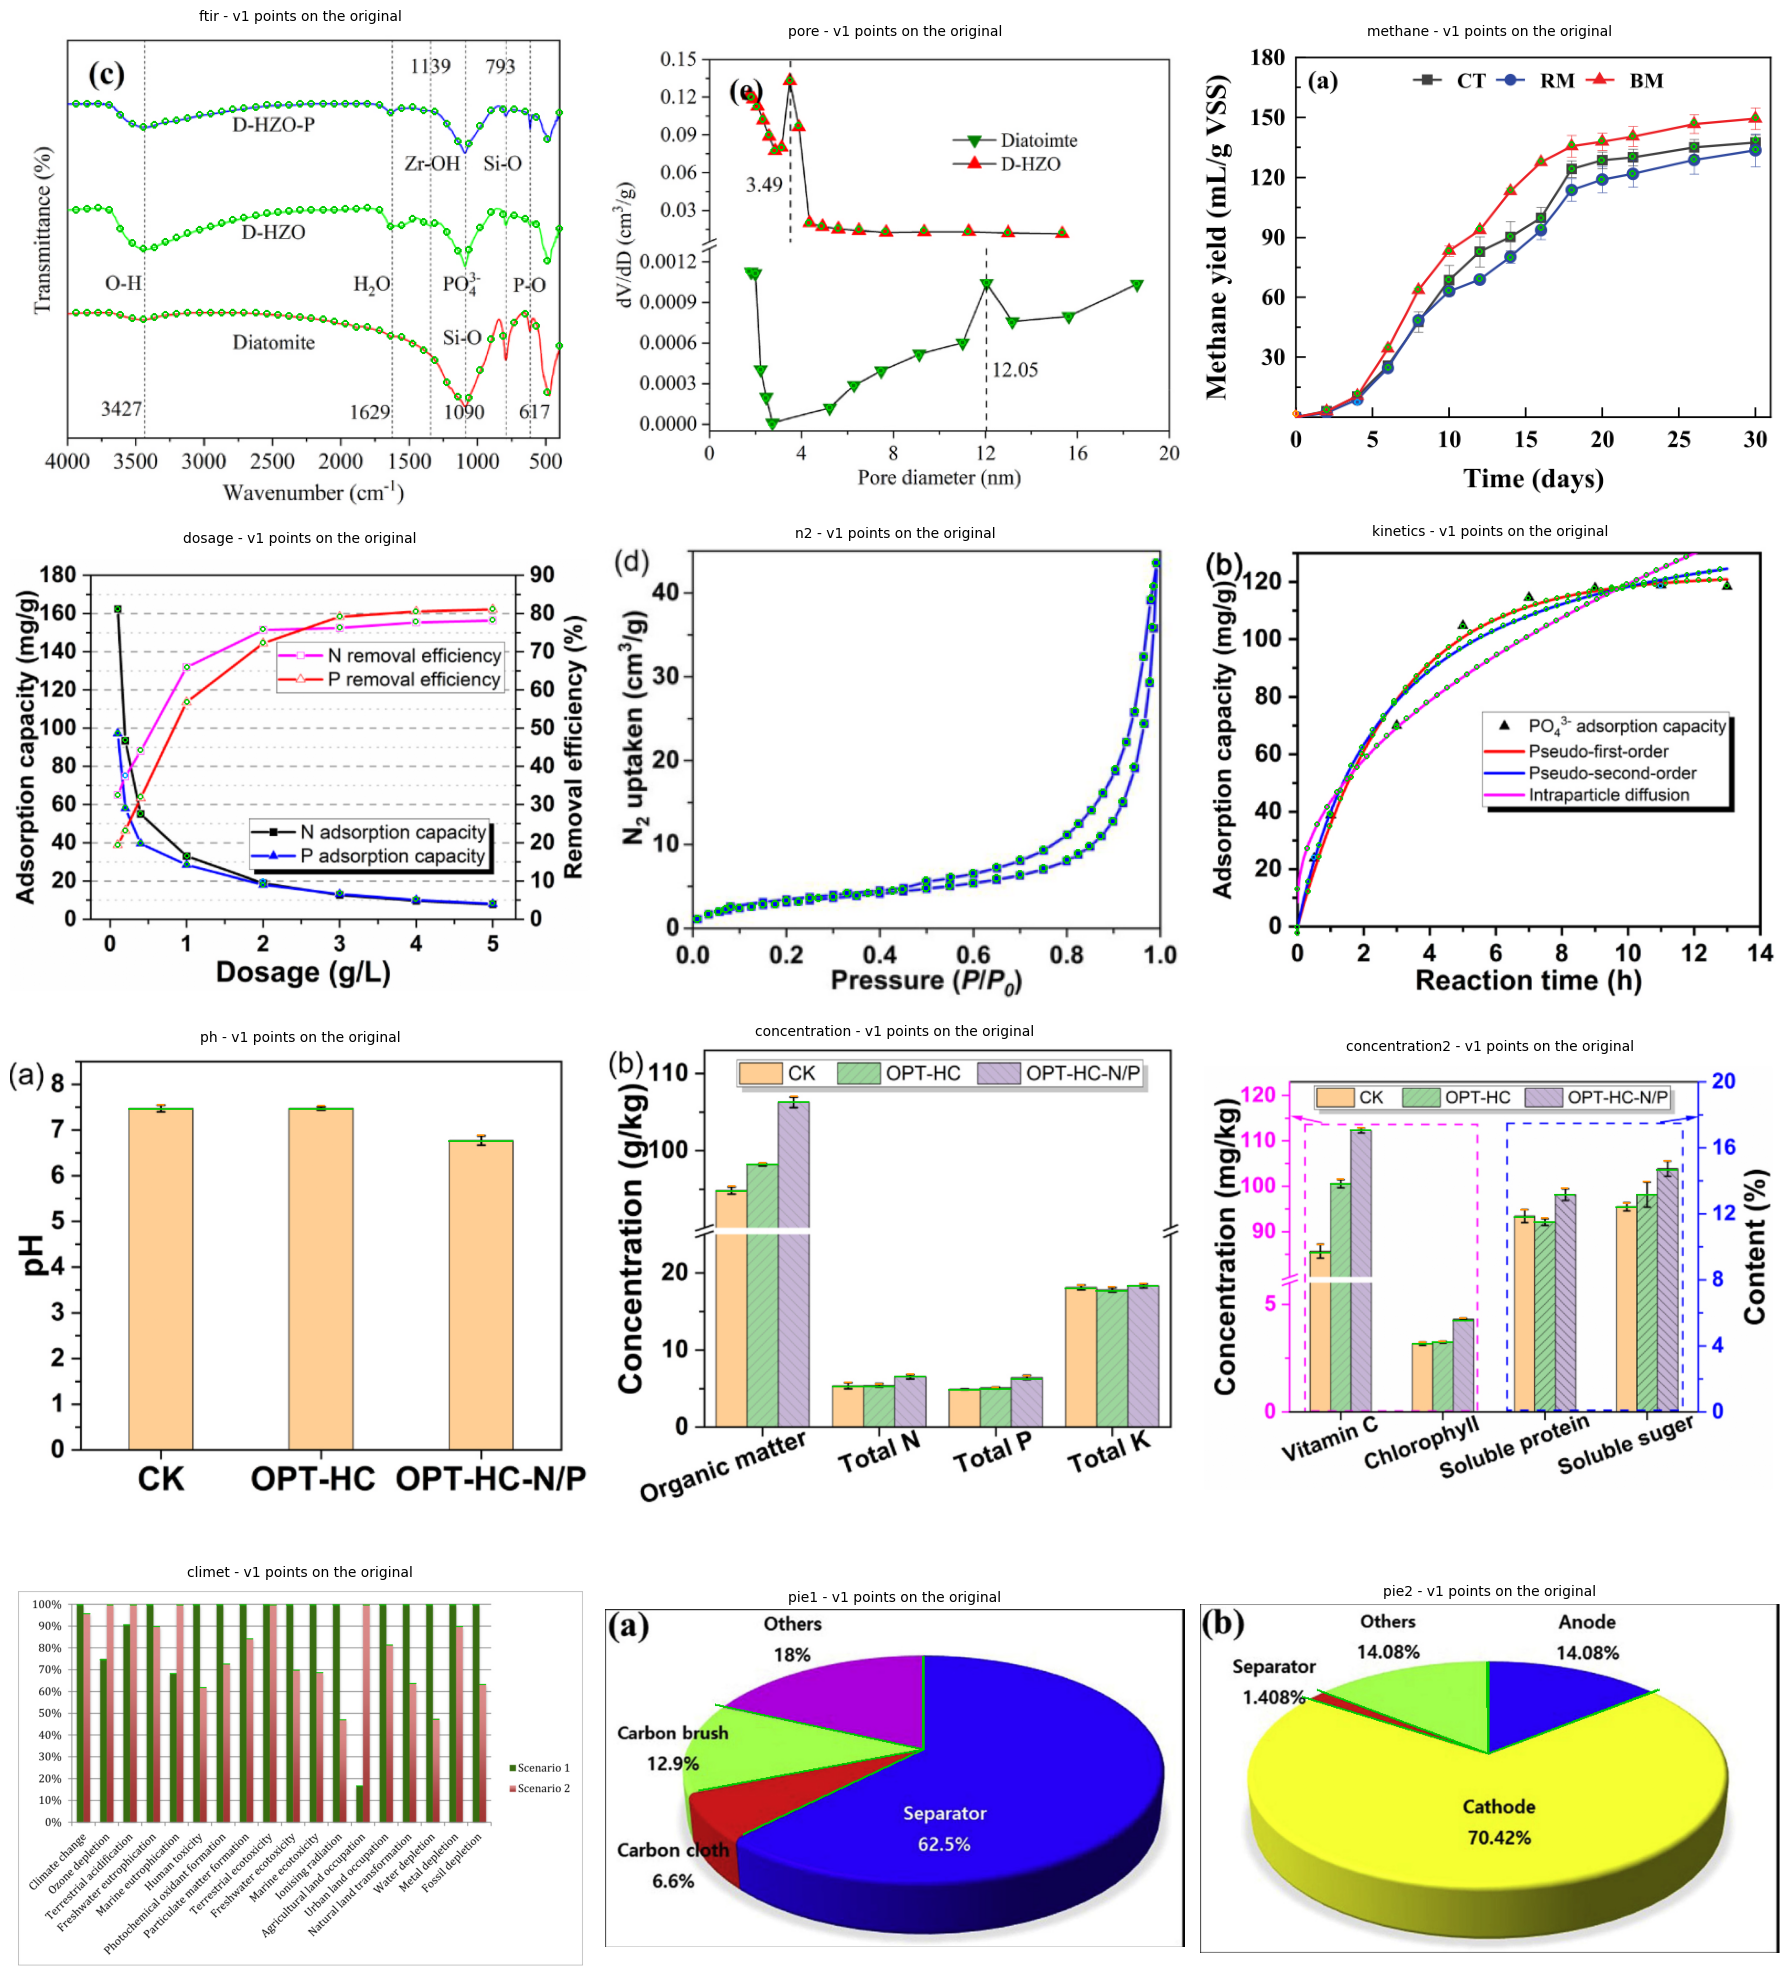

In [4]:
reference = pl.build_reference(P, force=False)
for f in ORDER:
    flags = [fl for s in reference[f]["series"].values() for fl in s.get("flags", [])]
    n = sum(len(s["x"]) for s in reference[f]["series"].values())
    extra = {k: flags.count(k) for k in sorted(set(flags)) if k != "detected"}
    print(f"{f:9s} {len(reference[f]['series'])} series, {n:4d} points  {extra if extra else ''}")
show_grid(pl.overlay_reference(P, reference), [f"{f} - v1 points on the original" for f in ORDER])

## Stage 2 — rebuild every figure from the v1 data

Left: original. Right: rebuilt from v1 data. The rebuilt image becomes the test image; the v1 data
behind it is saved to `outputs/ground_truth/` as its exact ground truth.

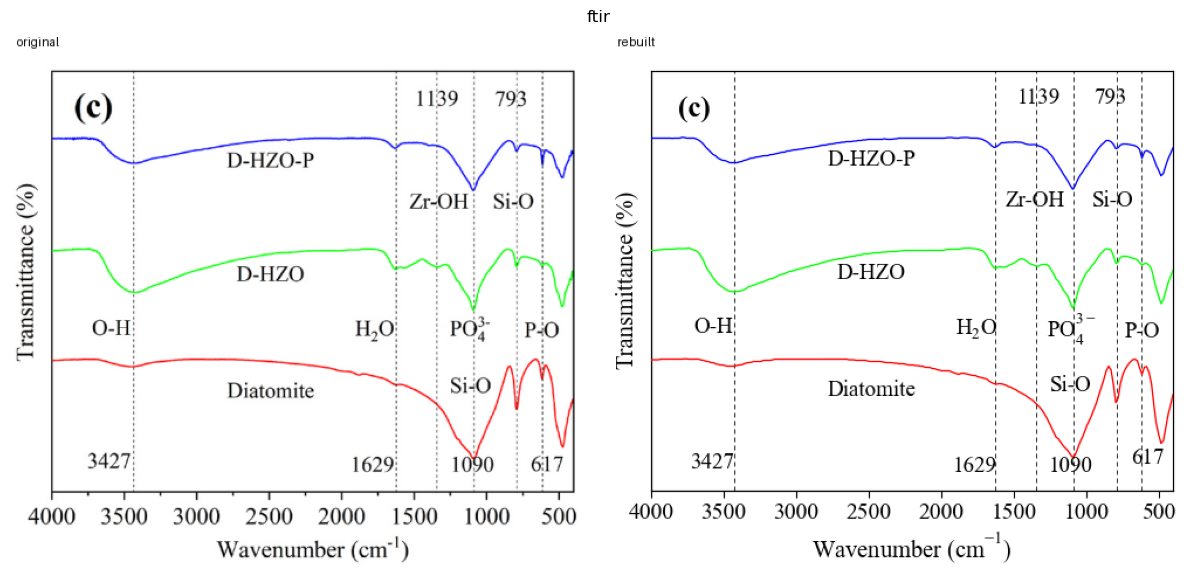

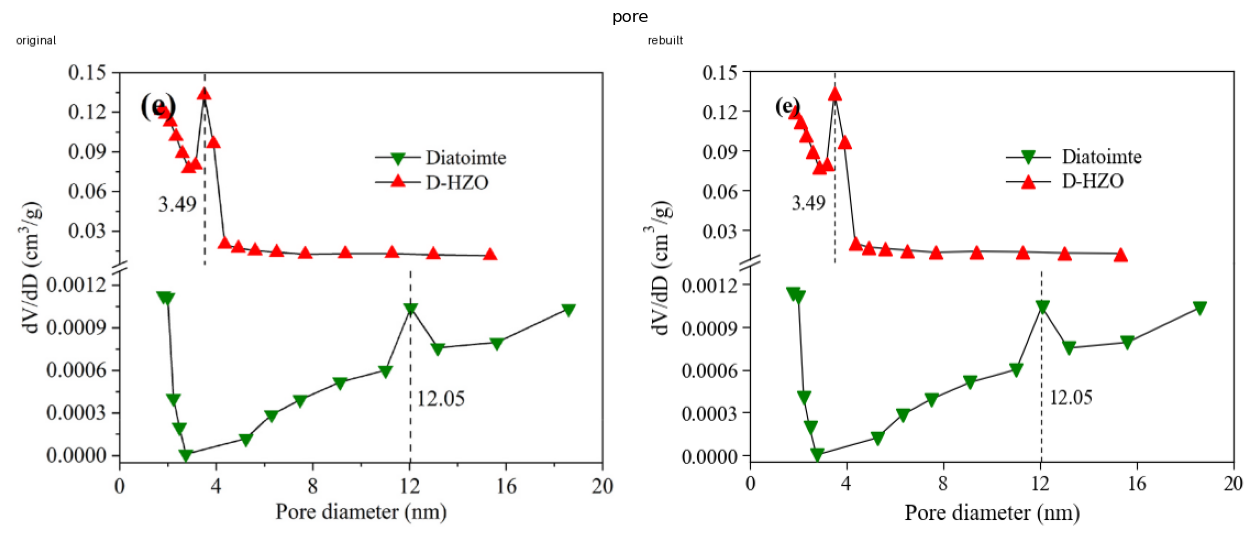

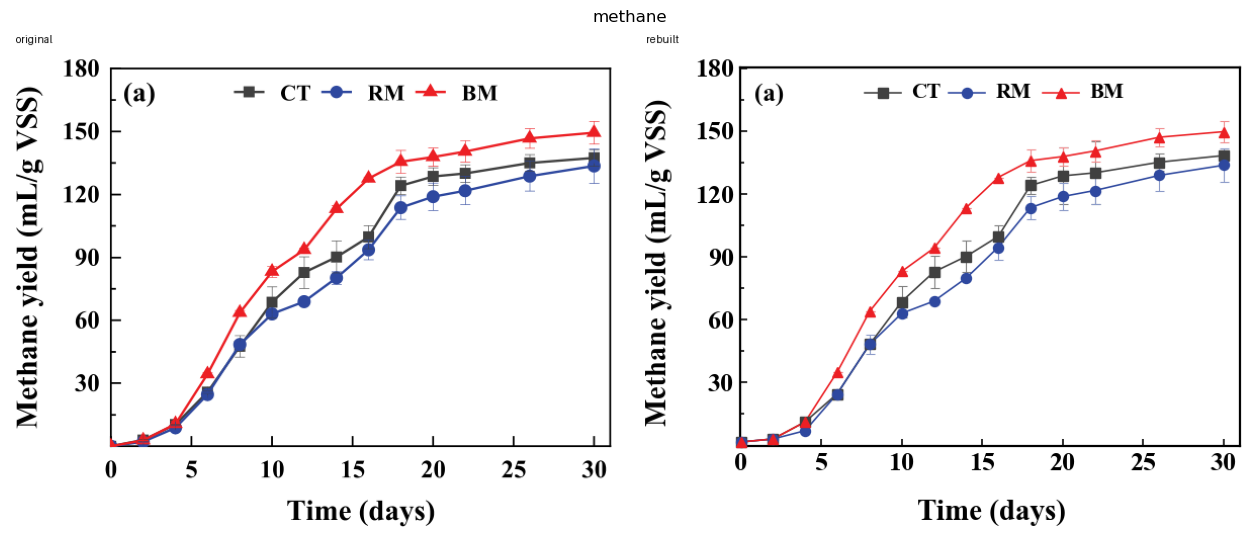

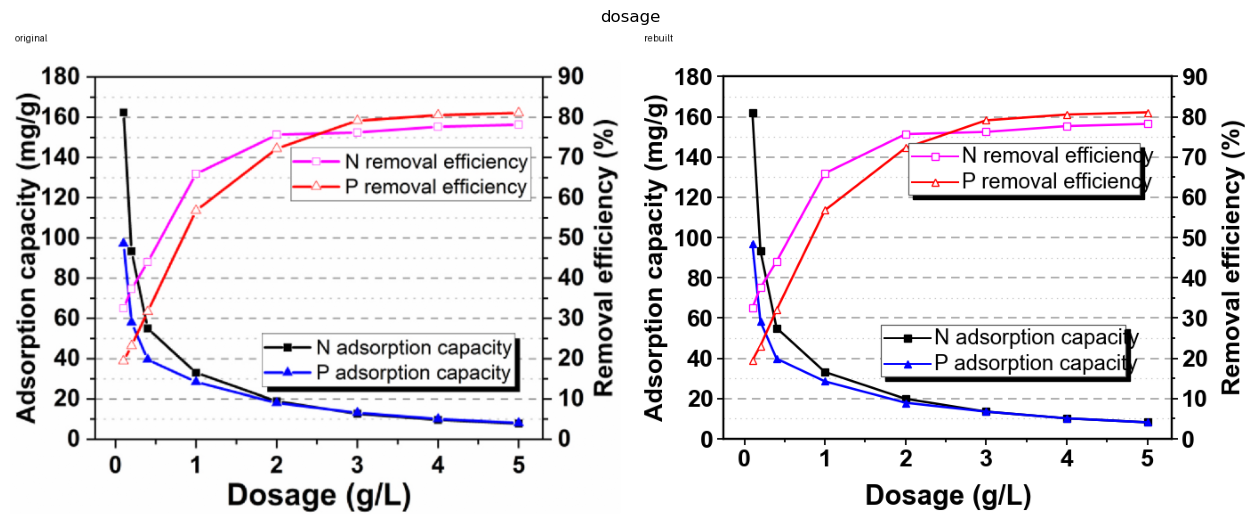

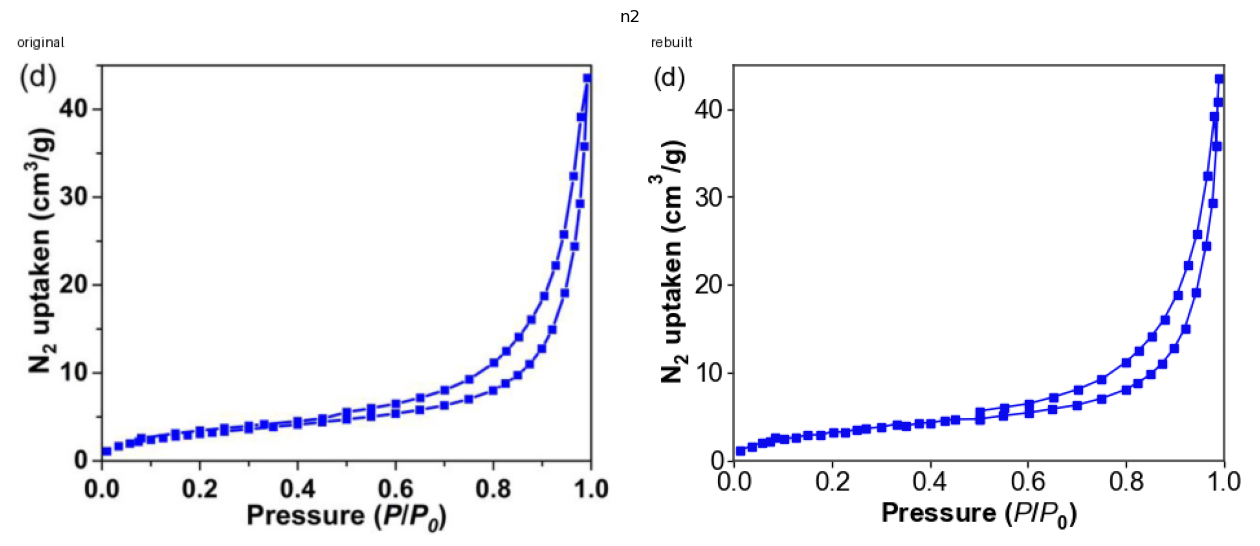

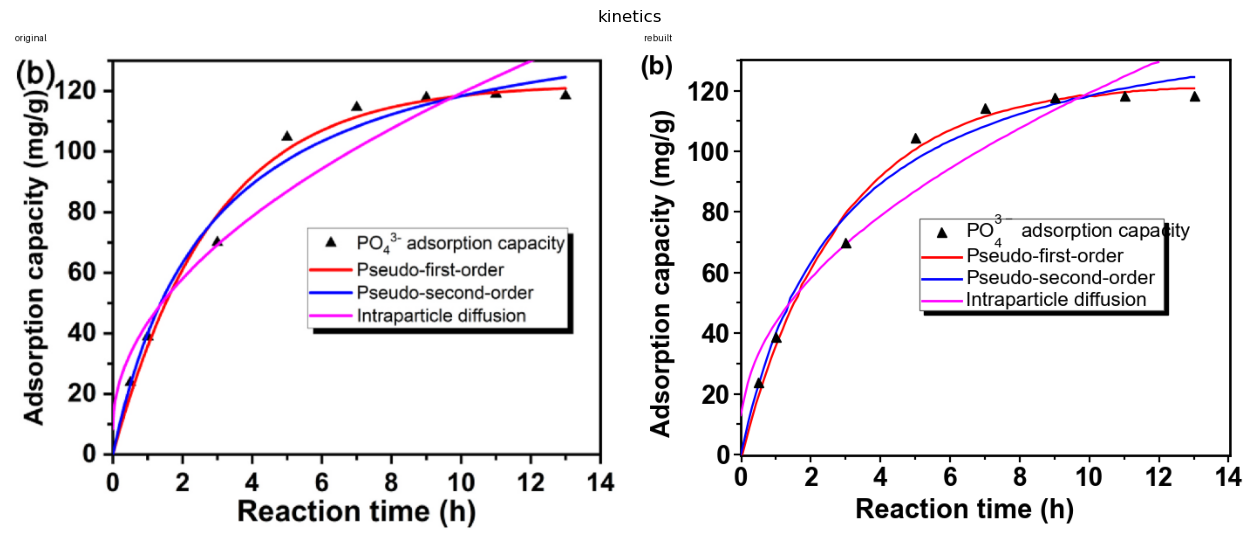

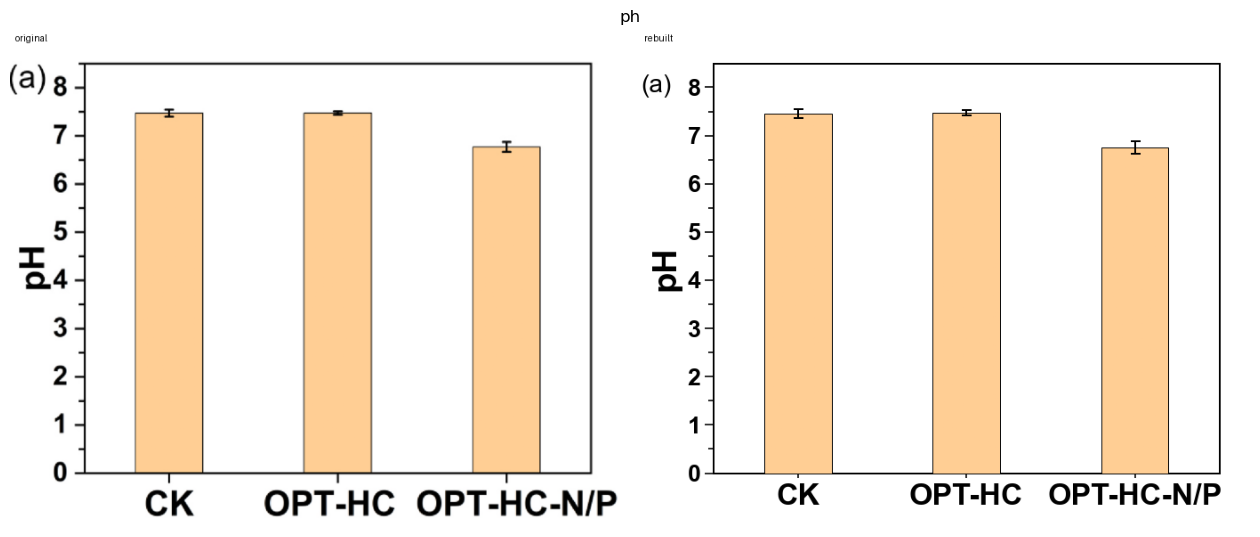

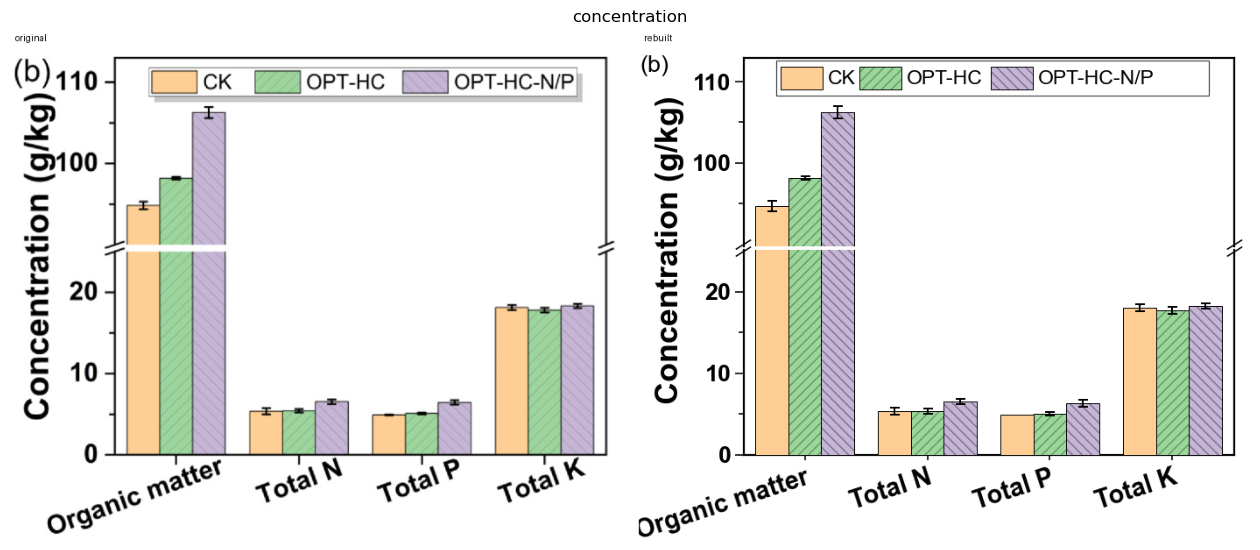

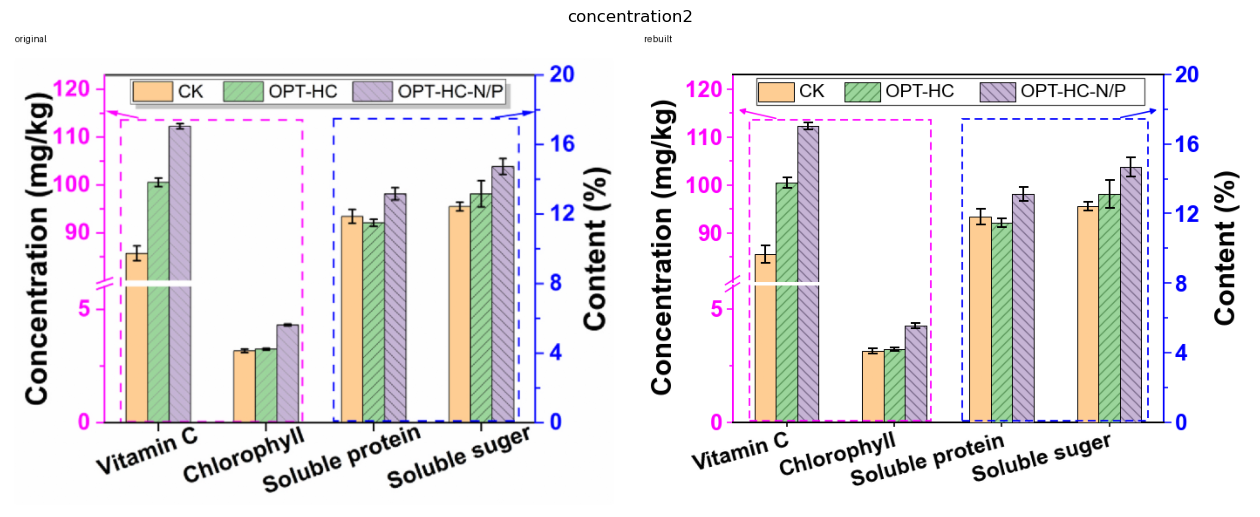

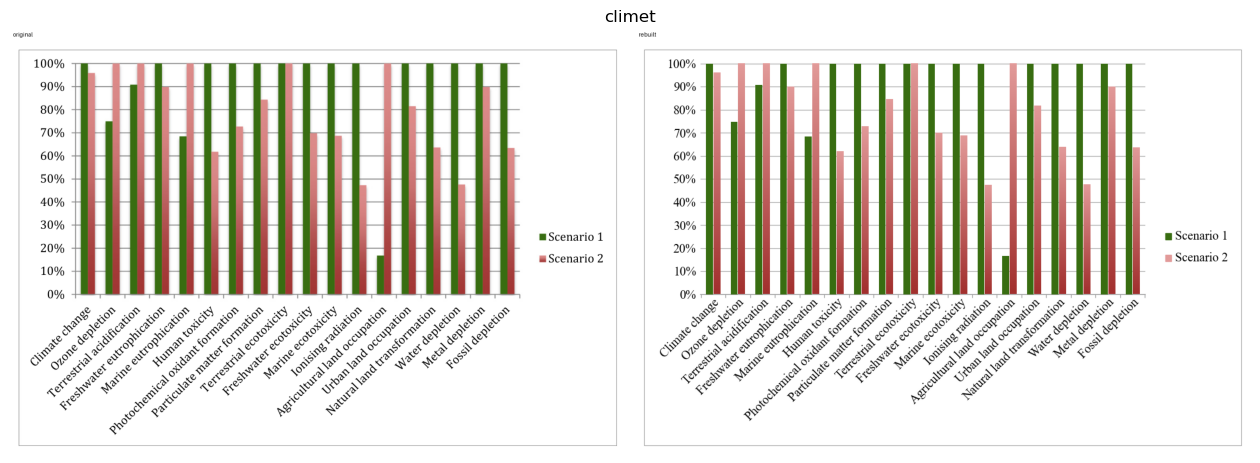

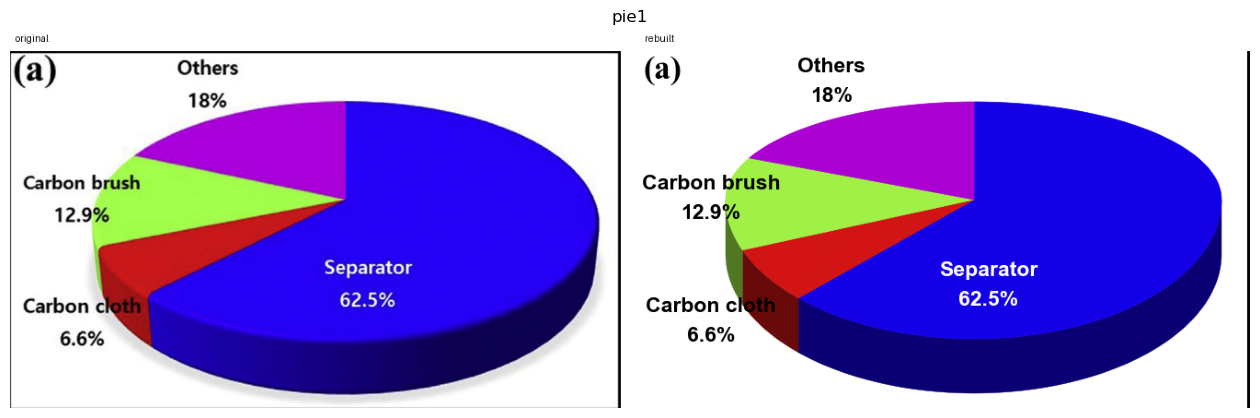

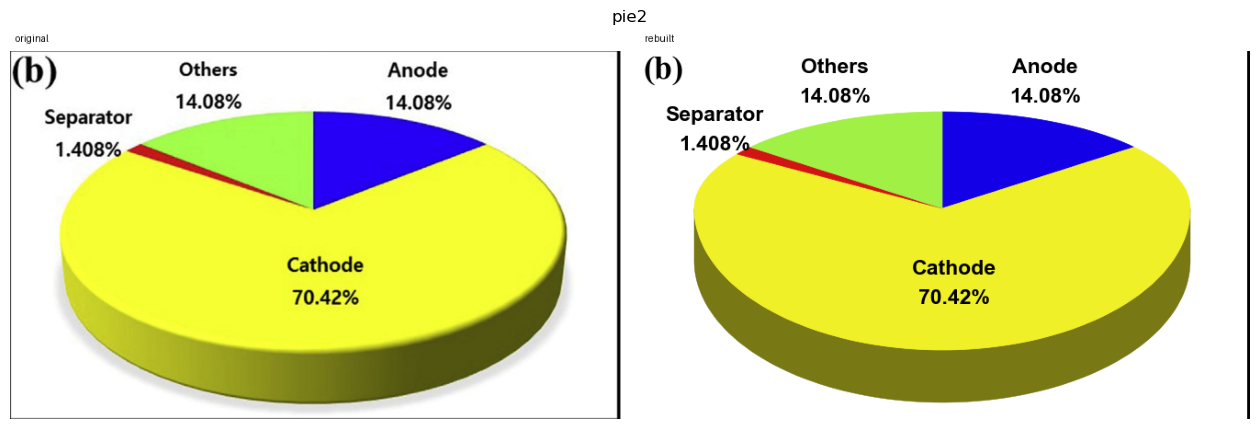

In [5]:
rebuilt = pl.rebuild_all(P, reference)
pairs = [pl.side_by_side(P, f, P.rebuilt_img(f), f"{f}_original_vs_rebuilt.png") for f in ORDER]
for f, p in zip(ORDER, pairs):
    plt.figure(figsize=(16, 7)); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.title(f); plt.show()